In [1]:
# Load libraries
import pandas as pd
import numpy as np

# Load the raw international results data
results = pd.read_csv("../data/raw/results.csv", parse_dates=["date"])

print("Rows and columns:", results.shape)
results.tail()

Rows and columns: (49945, 9)


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
49940,2026-10-06,Belize,French Guiana,0,1,CONCACAF Nations League,Belmopan,Belize,False
49941,2026-10-06,Turks and Caicos Islands,Montserrat,1,4,CONCACAF Nations League,Providenciales,Turks and Caicos Islands,False
49942,2026-10-06,Antigua and Barbuda,Aruba,3,2,CONCACAF Nations League,North Sound,Antigua and Barbuda,False
49943,2026-10-06,Saint Martin,Bahamas,6,0,CONCACAF Nations League,Saint Croix,United States Virgin Islands,True
49944,2026-10-06,Saudi Arabia,United Arab Emirates,2,0,Gulf Cup,Jeddah,Saudi Arabia,False


In [2]:
# Keep only the 2026 FIFA World Cup matches (these give us the target: goals)
wc = results[(results["tournament"] == "FIFA World Cup") &
             (results["date"] >= "2026-06-11")].copy()
wc = wc.sort_values("date").reset_index(drop=True)

print("World Cup 2026 matches:", len(wc))
print("First match:", wc["date"].min().date(), "| Last match:", wc["date"].max().date())
print("Number of teams:", pd.concat([wc["home_team"], wc["away_team"]]).nunique())
wc.head()

World Cup 2026 matches: 104
First match: 2026-06-11 | Last match: 2026-07-19
Number of teams: 48


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
0,2026-06-11,Mexico,South Africa,2,0,FIFA World Cup,Mexico City,Mexico,False
1,2026-06-11,South Korea,Czech Republic,2,1,FIFA World Cup,Zapopan,Mexico,True
2,2026-06-12,Canada,Bosnia and Herzegovina,1,1,FIFA World Cup,Toronto,Canada,False
3,2026-06-12,United States,Paraguay,4,1,FIFA World Cup,Inglewood,United States,False
4,2026-06-13,Qatar,Switzerland,1,1,FIFA World Cup,Santa Clara,United States,True


In [3]:
# Give each World Cup match an ID number (1 to 104, in date order)
wc["match_id"] = range(1, len(wc) + 1)

# One row from the home team's point of view
side_a = pd.DataFrame({
    "match_id": wc["match_id"],
    "date": wc["date"],
    "team": wc["home_team"],
    "opponent": wc["away_team"],
    "goals": wc["home_score"],      # TARGET: goals this team scored
})

# One row from the away team's point of view
side_b = pd.DataFrame({
    "match_id": wc["match_id"],
    "date": wc["date"],
    "team": wc["away_team"],
    "opponent": wc["home_team"],
    "goals": wc["away_score"],
})

# Stack them together: 104 + 104 = 208 rows
df = pd.concat([side_a, side_b]).sort_values("match_id").reset_index(drop=True)

# Checks
print("Rows and columns:", df.shape)
print("Rows per match:", df.groupby("match_id").size().unique())
print("Total goals in df:", df["goals"].sum(),
      "| Total goals in wc:", wc["home_score"].sum() + wc["away_score"].sum())
df.head(6)

Rows and columns: (208, 5)
Rows per match: [2]
Total goals in df: 308 | Total goals in wc: 308


,match_id,date,team,opponent,goals
0,1,2026-06-11,Mexico,South Africa,2
1,1,2026-06-11,South Africa,Mexico,0
2,2,2026-06-11,South Korea,Czech Republic,2
3,2,2026-06-11,Czech Republic,South Korea,1
4,3,2026-06-12,Canada,Bosnia and Herzegovina,1
5,3,2026-06-12,Bosnia and Herzegovina,Canada,1


In [4]:
# Only matches BEFORE the World Cup started (prevents data leakage)
WC_START = pd.Timestamp("2026-06-11")
before = results[results["date"] < WC_START].dropna(subset=["home_score", "away_score"])

# Write every past match twice: once for each team
home_view = pd.DataFrame({
    "date": before["date"], "team": before["home_team"], "opponent": before["away_team"],
    "scored": before["home_score"], "conceded": before["away_score"],
    "tournament": before["tournament"],
})
away_view = pd.DataFrame({
    "date": before["date"], "team": before["away_team"], "opponent": before["home_team"],
    "scored": before["away_score"], "conceded": before["home_score"],
    "tournament": before["tournament"],
})
history = pd.concat([home_view, away_view]).sort_values("date").reset_index(drop=True)

print("History rows:", history.shape)
print("Latest date in history:", history["date"].max().date())

History rows: (98950, 6)
Latest date in history: 2026-06-10


In [5]:
# Each team's last 10 matches before the World Cup
last10 = history.groupby("team").tail(10)
form10 = last10.groupby("team").agg(
    goals_pg_last10=("scored", "mean"),
    conceded_pg_last10=("conceded", "mean"),
    n_matches=("scored", "size"),
)

# Variable 3 (shared): this team's goals per game, last 10
df["team_goals_pg_last10"] = df["team"].map(form10["goals_pg_last10"])
# Variable 5 (unique): the OPPONENT's goals conceded per game, last 10
df["opp_conceded_pg10"] = df["opponent"].map(form10["conceded_pg_last10"])

# Checks
wc_teams = df["team"].unique()
print("Teams with fewer than 10 past matches:",
      list(form10.loc[wc_teams].query("n_matches < 10").index))
print("Missing values:", df[["team_goals_pg_last10", "opp_conceded_pg10"]].isna().sum().to_dict())
df.head(4)

Teams with fewer than 10 past matches: []
Missing values: {'team_goals_pg_last10': 0, 'opp_conceded_pg10': 0}


,match_id,date,team,opponent,goals,team_goals_pg_last10,opp_conceded_pg10
0,1,2026-06-11,Mexico,South Africa,2,1.6,1.0
1,1,2026-06-11,South Africa,Mexico,0,1.5,0.4
2,2,2026-06-11,South Korea,Czech Republic,2,1.5,0.9
3,2,2026-06-11,Czech Republic,South Korea,1,2.2,1.2


In [6]:
# Put every team's past matches and World Cup matches on one timeline
timeline = pd.concat([history[["date", "team"]], df[["date", "team"]]])
timeline = timeline.drop_duplicates().sort_values(["team", "date"])

# Days since each team's previous match
timeline["prev_date"] = timeline.groupby("team")["date"].shift(1)
timeline["rest_days"] = (timeline["date"] - timeline["prev_date"]).dt.days

# Variable 4 (shared): attach rest days to the World Cup rows
df = df.merge(timeline[["team", "date", "rest_days"]], on=["team", "date"], how="left")

# Checks
print("Rows:", len(df), "| Missing rest_days:", df["rest_days"].isna().sum())
print(df["rest_days"].describe().round(1))
print("\nLongest rest before a match:")
print(df.nlargest(5, "rest_days")[["team", "date", "rest_days"]])


Rows: 208 | Missing rest_days: 0
count    208.0
mean       6.3
std        5.2
min        3.0
25%        5.0
50%        6.0
75%        6.2
max       76.0
Name: rest_days, dtype: float64

Longest rest before a match:
       team       date  rest_days
24  Uruguay 2026-06-15       76.0
38  Austria 2026-06-16       15.0
46    Ghana 2026-06-17       15.0
20    Japan 2026-06-14       14.0
31     Iran 2026-06-15       11.0


In [7]:
# Matches since the 2022 World Cup final (19 Dec 2022 to 10 Jun 2026)
since22 = history[history["date"] >= "2022-12-19"]

# Variable 8 (unique): share of this team's matches where it scored 0
fail_rate = since22.groupby("team")["scored"].apply(lambda s: (s == 0).mean())
df["team_fail_to_score_rate"] = df["team"].map(fail_rate)

# Variable 6 (unique): opponent's goals per game in competitive matches (no friendlies)
competitive = since22[since22["tournament"] != "Friendly"]
gpg_comp = competitive.groupby("team")["scored"].mean()
df["opp_gpg_competitive"] = df["opponent"].map(gpg_comp)

# Variable 7 (unique): number of World Cups the opponent played from 1998 to 2022
past_wc = history[(history["tournament"] == "FIFA World Cup") & (history["date"].dt.year >= 1998)]
wc_apps = past_wc.groupby("team")["date"].apply(lambda d: d.dt.year.nunique())
df["opp_wc_apps_since1998"] = df["opponent"].map(wc_apps).fillna(0).astype(int)

# Checks
cols = ["team_fail_to_score_rate", "opp_gpg_competitive", "opp_wc_apps_since1998"]
print("Missing values:", df[cols].isna().sum().to_dict())
print("World Cup appearances range:", df["opp_wc_apps_since1998"].min(), "to", df["opp_wc_apps_since1998"].max())
print("Matches since 2022 per team (smallest):", since22.groupby("team").size().loc[wc_teams].min())
df[["team", "opponent"] + cols].head(4)

Missing values: {'team_fail_to_score_rate': 0, 'opp_gpg_competitive': 0, 'opp_wc_apps_since1998': 0}
World Cup appearances range: 0 to 7
Matches since 2022 per team (smallest): 33


,team,opponent,team_fail_to_score_rate,opp_gpg_competitive,opp_wc_apps_since1998
0,Mexico,South Africa,0.245614,1.621622,3
1,South Africa,Mexico,0.285714,1.555556,7
2,South Korea,Czech Republic,0.170732,1.703704,1
3,Czech Republic,South Korea,0.108108,2.318182,7


In [29]:
# Hand-collected inputs for the 48 teams:
#   fifa_points        = FIFA/Coca-Cola Men's World Ranking points, 11 June 2026 edition
#   market_value_eur_m = Transfermarkt squad value (€ millions), Wayback Machine snapshot 12 June 2026
# Raw source pages are saved in data/raw/ (fifa_ranking_2026-06-11_raw.txt, transfermarkt_wc2026_participants_raw.txt)
manual_rows = [
    ("Algeria", 1571.03, 256.9),
    ("Argentina", 1877.27, 807.5),
    ("Australia", 1579.34, 77.45),
    ("Austria", 1597.4, 245.2),
    ("Belgium", 1742.24, 547.5),
    ("Bosnia and Herzegovina", 1387.22, 151.6),
    ("Brazil", 1765.86, 928.2),
    ("Canada", 1559.48, 198.65),
    ("Cape Verde", 1371.11, 54.5),
    ("Colombia", 1698.35, 302.35),
    ("Croatia", 1714.87, 387.3),
    ("Curaçao", 1294.77, 25.78),
    ("Czech Republic", 1505.74, 188.18),
    ("DR Congo", 1474.43, 143.9),
    ("Ecuador", 1598.52, 368.7),
    ("Egypt", 1562.37, 116.48),
    ("England", 1828.02, 1360.0),
    ("France", 1870.7, 1520.0),
    ("Germany", 1735.77, 947.0),
    ("Ghana", 1346.88, 234.6),
    ("Haiti", 1293.1, 55.9),
    ("Iran", 1619.58, 32.05),
    ("Iraq", 1446.28, 21.2),
    ("Ivory Coast", 1540.87, 522.1),
    ("Japan", 1661.58, 266.85),
    ("Jordan", 1387.74, 20.3),
    ("Mexico", 1687.48, 191.85),
    ("Morocco", 1755.1, 447.7),
    ("Netherlands", 1753.57, 754.2),
    ("New Zealand", 1275.58, 34.35),
    ("Norway", 1557.44, 589.9),
    ("Panama", 1539.16, 34.55),
    ("Paraguay", 1505.35, 153.65),
    ("Portugal", 1767.85, 1010.0),
    ("Qatar", 1450.31, 19.93),
    ("Saudi Arabia", 1423.88, 40.68),
    ("Scotland", 1503.34, 170.25),
    ("Senegal", 1684.07, 478.1),
    ("South Africa", 1428.38, 49.25),
    ("South Korea", 1591.63, 139.05),
    ("Spain", 1874.71, 1220.0),
    ("Sweden", 1509.79, 406.08),
    ("Switzerland", 1650.06, 332.5),
    ("Tunisia", 1476.41, 69.95),
    ("Turkey", 1605.73, 473.7),
    ("United States", 1671.23, 385.65),
    ("Uruguay", 1673.07, 359.3),
    ("Uzbekistan", 1458.73, 85.33),
]
manual_inputs = pd.DataFrame(manual_rows, columns=["team", "fifa_points", "market_value_eur_m"])
manual_inputs.to_csv("../data/raw/team_manual_inputs.csv", index=False, encoding="utf-8-sig")
print("Saved", len(manual_inputs), "teams | missing:", manual_inputs.isna().sum().sum())

Saved 48 teams | missing: 0


In [18]:
# Load the hand-collected inputs (FIFA points 11 June 2026; Transfermarkt values 12 June 2026)
manual = pd.read_csv("../data/raw/team_manual_inputs.csv", encoding="utf-8-sig")
print("Manual file:", manual.shape, "| missing:", manual.isna().sum().to_dict())

# Variables 1 and 2 (shared): this team's FIFA points and squad market value (€ millions)
df["team_fifa_points"] = df["team"].map(manual.set_index("team")["fifa_points"])
df["team_market_value"] = df["team"].map(manual.set_index("team")["market_value_eur_m"])

print("Missing after join:", df[["team_fifa_points", "team_market_value"]].isna().sum().to_dict())
df[["team", "opponent", "goals", "team_fifa_points", "team_market_value"]].head(4)

Manual file: (48, 3) | missing: {'team': 0, 'fifa_points': 0, 'market_value_eur_m': 0}
Missing after join: {'team_fifa_points': 0, 'team_market_value': 0}


,team,opponent,goals,team_fifa_points,team_market_value
0,Mexico,South Africa,2,1687.48,191.85
1,South Africa,Mexico,0,1428.38,49.25
2,South Korea,Czech Republic,2,1591.63,139.05
3,Czech Republic,South Korea,1,1505.74,188.18


In [19]:
# ---- FINAL DATASET: target + exactly 8 explanatory variables ----
TARGET = "goals"
FEATURES = [
    "team_fifa_points",         # 1 shared  - FIFA ranking points (11 Jun 2026)
    "team_market_value",        # 2 shared  - squad market value, € millions
    "team_goals_pg_last10",     # 3 shared  - goals per game, last 10 matches
    "rest_days",                # 4 shared  - days since previous match
    "opp_conceded_pg10",        # 5 unique  - opponent goals conceded per game, last 10
    "opp_gpg_competitive",      # 6 unique  - opponent goals per competitive game since 2022
    "opp_wc_apps_since1998",    # 7 unique  - opponent World Cups played 1998-2022
    "team_fail_to_score_rate",  # 8 unique  - share of matches since 2022 with 0 goals
]

final = df[["match_id", "date", "team", "opponent", TARGET] + FEATURES]

# Checks required by the brief
print("Rows:", len(final), "(should be 208)")
print("Number of explanatory variables:", len(FEATURES), "(should be 8)")
print("Missing values:", final.isna().sum().sum(), "(should be 0)")
print("\nData types:")
print(final[[TARGET] + FEATURES].dtypes)

# Save the processed dataset
final.to_csv("../data/processed/reg_2_2_dataset.csv", index=False, encoding="utf-8-sig")

Rows: 208 (should be 208)
Number of explanatory variables: 8 (should be 8)
Missing values: 0 (should be 0)

Data types:
goals                        int64
team_fifa_points           float64
team_market_value          float64
team_goals_pg_last10       float64
rest_days                  float64
opp_conceded_pg10          float64
opp_gpg_competitive        float64
opp_wc_apps_since1998        int64
team_fail_to_score_rate    float64
dtype: object


goals
0    55
1    71
2    39
3    25
4    10
5     5
6     2
7     1
Name: count, dtype: int64

Average goals per team per match: 1.48


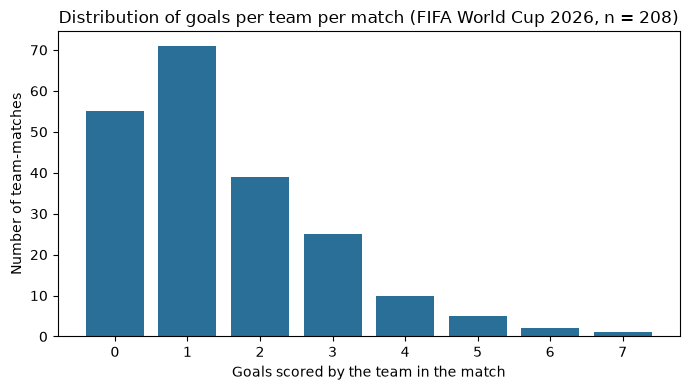

In [20]:
import matplotlib.pyplot as plt

# How many goals do teams usually score in one World Cup match?
print(final["goals"].value_counts().sort_index())
print("\nAverage goals per team per match:", round(final["goals"].mean(), 2))

fig, ax = plt.subplots(figsize=(7, 4))
counts = final["goals"].value_counts().sort_index()
ax.bar(counts.index, counts.values, color="#2a6f97")
ax.set_xlabel("Goals scored by the team in the match")
ax.set_ylabel("Number of team-matches")
ax.set_title("Distribution of goals per team per match (FIFA World Cup 2026, n = 208)")
ax.set_xticks(counts.index)
plt.tight_layout()
plt.savefig("../outputs/figures/01_goals_distribution.png", dpi=150)
plt.show()

Correlation with goals:
team_fifa_points           0.385
team_market_value          0.375
opp_wc_apps_since1998     -0.326
team_fail_to_score_rate   -0.324
team_goals_pg_last10       0.303
opp_conceded_pg10          0.254
opp_gpg_competitive       -0.030
rest_days                 -0.013
Name: goals, dtype: float64


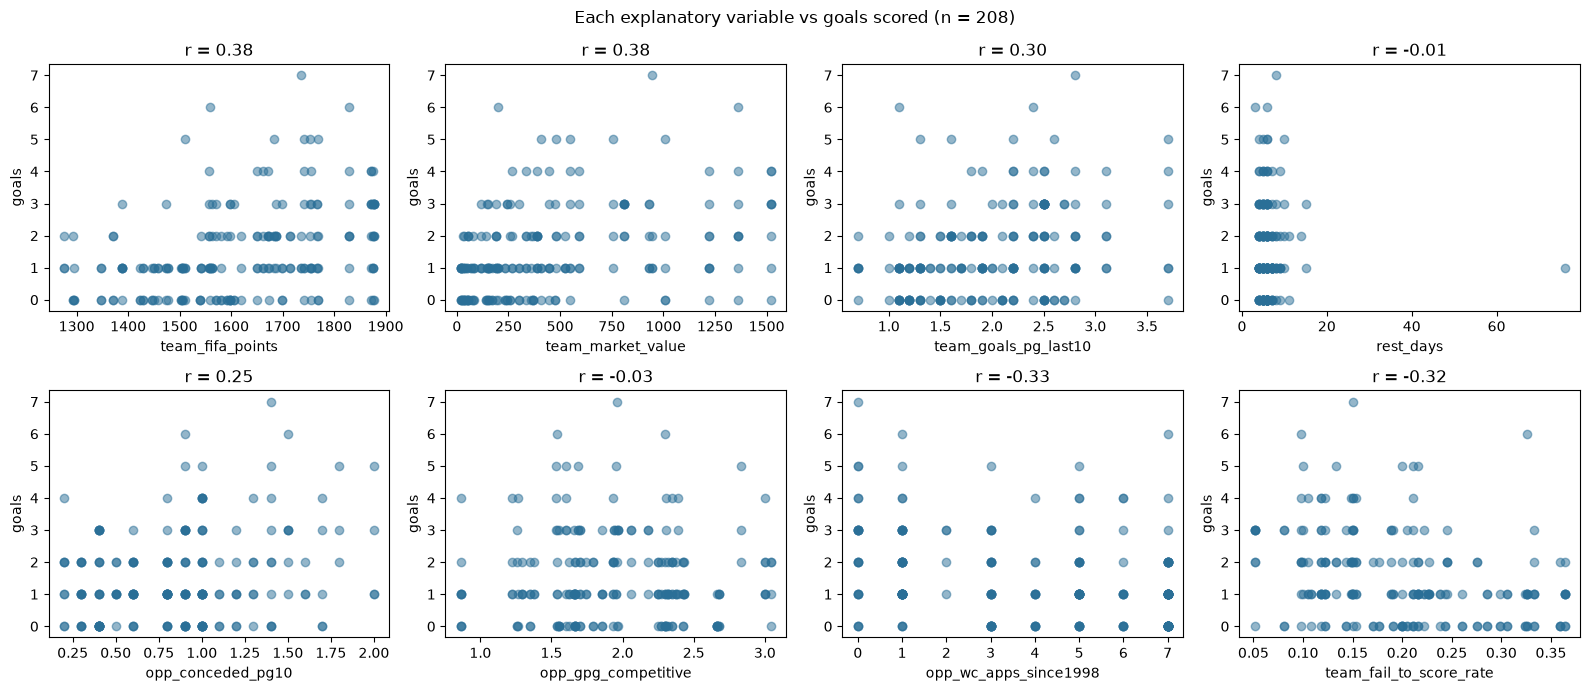

In [21]:
# Correlation of each explanatory variable with goals (from strongest to weakest)
corr = final[FEATURES + ["goals"]].corr()["goals"].drop("goals").sort_values(key=abs, ascending=False)
print("Correlation with goals:")
print(corr.round(3))

# Scatter plot of each variable against goals
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, FEATURES):
    ax.scatter(final[col], final["goals"], alpha=0.5, color="#2a6f97")
    ax.set_xlabel(col)
    ax.set_ylabel("goals")
    ax.set_title(f"r = {corr[col]:.2f}")
plt.suptitle("Each explanatory variable vs goals scored (n = 208)")
plt.tight_layout()
plt.savefig("../outputs/figures/02_variables_vs_goals.png", dpi=150)
plt.show()

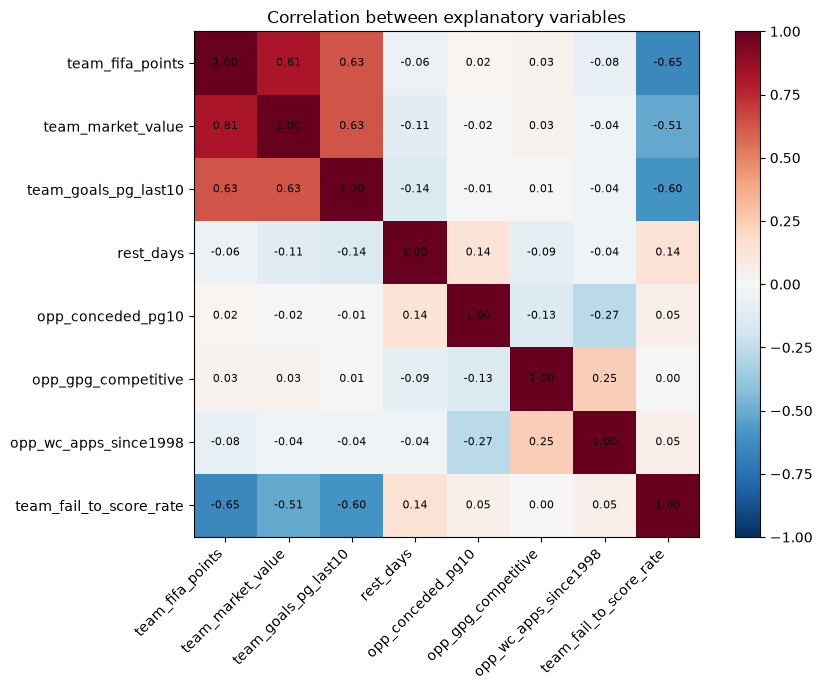

Strongly related pairs (|r| > 0.7):
team_fifa_points  team_market_value    0.81
dtype: float64


In [22]:
# Correlation between the explanatory variables themselves
pred_corr = final[FEATURES].corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(pred_corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)))
ax.set_xticklabels(FEATURES, rotation=45, ha="right")
ax.set_yticks(range(len(FEATURES)))
ax.set_yticklabels(FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{pred_corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im)
ax.set_title("Correlation between explanatory variables")
plt.tight_layout()
plt.savefig("../outputs/figures/03_predictor_correlation.png", dpi=150)
plt.show()

# List any pair that is strongly related (|r| > 0.7)
pairs = pred_corr.where(np.triu(np.ones(pred_corr.shape, dtype=bool), k=1)).stack()
print("Strongly related pairs (|r| > 0.7):")
print(pairs[pairs.abs() > 0.7].round(2) if (pairs.abs() > 0.7).any() else "None")

In [23]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

X_vif = sm.add_constant(final[FEATURES])
vif = pd.DataFrame({
    "variable": FEATURES,
    "VIF": [variance_inflation_factor(X_vif.values, i + 1) for i in range(len(FEATURES))],
}).sort_values("VIF", ascending=False)
print(vif.round(2).to_string(index=False))
vif.round(2).to_csv("../outputs/model_results/vif.csv", index=False)

               variable  VIF
       team_fifa_points 3.89
      team_market_value 3.24
   team_goals_pg_last10 2.02
team_fail_to_score_rate 1.98
  opp_wc_apps_since1998 1.14
      opp_conceded_pg10 1.11
    opp_gpg_competitive 1.08
              rest_days 1.06


In [24]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = final[FEATURES]
y = final["goals"]

# Split 80% train / 20% test BY MATCH, so both rows of a match stay together
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=final["match_id"]))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
print("Train rows:", len(X_train), "| Test rows:", len(X_test))

# Fit the model on the training data only
model = LinearRegression().fit(X_train, y_train)

# Evaluate on train and test
def scores(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)}

results = pd.DataFrame({
    "Train": scores(y_train, model.predict(X_train)),
    "Test": scores(y_test, model.predict(X_test)),
    # Baseline: always predict the average goals from training data
    "Baseline (test)": scores(y_test, np.full(len(y_test), y_train.mean())),
}).round(3)
print(results)
results.to_csv("../outputs/model_results/metrics.csv")

Train rows: 166 | Test rows: 42
      Train   Test  Baseline (test)
MAE   0.909  0.885            1.051
RMSE  1.202  1.043            1.186
R2    0.304  0.094           -0.171


In [25]:
from sklearn.model_selection import GroupKFold, cross_validate

# Test the model 5 times on 5 different groups of matches, then average
cv = cross_validate(
    LinearRegression(), X, y,
    groups=final["match_id"], cv=GroupKFold(n_splits=5),
    scoring={"MAE": "neg_mean_absolute_error",
             "RMSE": "neg_root_mean_squared_error",
             "R2": "r2"},
)

cv_results = pd.DataFrame({
    "MAE": -cv["test_MAE"],
    "RMSE": -cv["test_RMSE"],
    "R2": cv["test_R2"],
}, index=[f"Fold {i}" for i in range(1, 6)])
cv_results.loc["Mean"] = cv_results.mean()
cv_results.loc["Std"] = cv_results.iloc[:5].std()

print(cv_results.round(3))
cv_results.round(3).to_csv("../outputs/model_results/cv_metrics.csv")


          MAE   RMSE     R2
Fold 1  1.027  1.363  0.238
Fold 2  0.863  1.182  0.271
Fold 3  0.843  1.131  0.111
Fold 4  0.933  1.135  0.220
Fold 5  0.893  1.215  0.325
Mean    0.912  1.205  0.233
Std     0.073  0.095  0.079


                            OLS Regression Results                            
Dep. Variable:                  goals   R-squared:                       0.299
Model:                            OLS   Adj. R-squared:                  0.271
Method:                 Least Squares   F-statistic:                     10.61
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           2.20e-12
Time:                        14:17:36   Log-Likelihood:                -326.69
No. Observations:                 208   AIC:                             671.4
Df Residuals:                     199   BIC:                             701.4
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                     

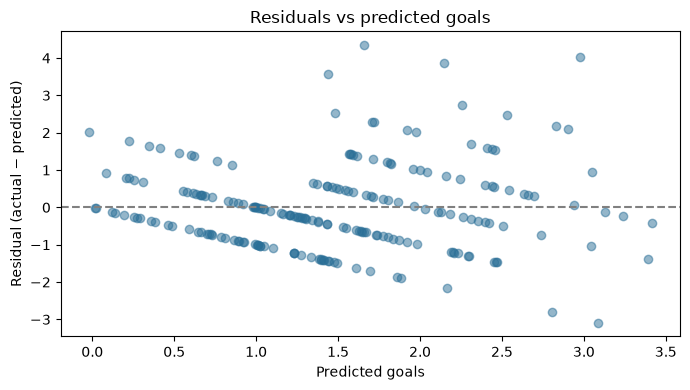

In [26]:
# Full model with statistics (all 208 rows)
ols = sm.OLS(y, sm.add_constant(X)).fit()
print(ols.summary())

# Standardised coefficients: effect of a 1 SD change in each variable (in goals)
coef_table = pd.DataFrame({
    "coef": ols.params.drop("const"),
    "p_value": ols.pvalues.drop("const"),
    "std_coef": ols.params.drop("const") * X.std(),
}).sort_values("std_coef", key=abs, ascending=False)
print("\n", coef_table.round(4))
coef_table.round(4).to_csv("../outputs/model_results/coefficients.csv")

# Residual plot: are the errors random?
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(ols.fittedvalues, ols.resid, alpha=0.5, color="#2a6f97")
ax.axhline(0, color="grey", linestyle="--")
ax.set_xlabel("Predicted goals")
ax.set_ylabel("Residual (actual − predicted)")
ax.set_title("Residuals vs predicted goals")
plt.tight_layout()
plt.savefig("../outputs/figures/04_residuals.png", dpi=150)
plt.show()

In [27]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, PoissonRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, cross_validate

# Load the final saved dataset (so this cell works on its own)
final = pd.read_csv("../data/processed/reg_2_2_dataset.csv", encoding="utf-8-sig")
FEATURES = ["team_fifa_points", "team_market_value", "team_goals_pg_last10", "rest_days",
            "opp_conceded_pg10", "opp_gpg_competitive", "opp_wc_apps_since1998",
            "team_fail_to_score_rate"]
X = final[FEATURES]
y = final["goals"]

# Feature transformation: log of market value (very right-skewed), cap rest days at 14 (Uruguay outlier)
X_t = X.copy()
X_t["team_market_value"] = np.log(X_t["team_market_value"])
X_t["rest_days"] = X_t["rest_days"].clip(upper=14)

models = {
    "1. Linear (original)":      (make_pipeline(StandardScaler(), LinearRegression()), X),
    "2. Linear (transformed)":   (make_pipeline(StandardScaler(), LinearRegression()), X_t),
    "3. Ridge (transformed)":    (make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 50))), X_t),
    "4. Lasso (transformed)":    (make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=42)), X_t),
    "5. Poisson (transformed)":  (make_pipeline(StandardScaler(), PoissonRegressor(alpha=0.01, max_iter=1000)), X_t),
}

rows = []
for name, (m, Xm) in models.items():
    s = cross_validate(m, Xm, y, groups=final["match_id"], cv=GroupKFold(n_splits=5),
                       scoring={"MAE": "neg_mean_absolute_error",
                                "RMSE": "neg_root_mean_squared_error", "R2": "r2"})
    rows.append({"Model": name, "MAE": -s["test_MAE"].mean(),
                 "RMSE": -s["test_RMSE"].mean(), "R2": s["test_R2"].mean()})

comparison = pd.DataFrame(rows).set_index("Model").round(3)
print(comparison)
comparison.to_csv("../outputs/model_results/model_comparison.csv")

                            MAE   RMSE     R2
Model                                        
1. Linear (original)      0.912  1.205  0.233
2. Linear (transformed)   0.903  1.192  0.254
3. Ridge (transformed)    0.899  1.188  0.259
4. Lasso (transformed)    0.902  1.184  0.264
5. Poisson (transformed)  0.903  1.189  0.257


In [28]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, PoissonRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, cross_validate

# Load the final saved dataset (so this cell works on its own)
final = pd.read_csv("../data/processed/reg_2_2_dataset.csv", encoding="utf-8-sig")
FEATURES = ["team_fifa_points", "team_market_value", "team_goals_pg_last10", "rest_days",
            "opp_conceded_pg10", "opp_gpg_competitive", "opp_wc_apps_since1998",
            "team_fail_to_score_rate"]
X = final[FEATURES]
y = final["goals"]

# Feature transformation: log of market value (very right-skewed), cap rest days at 14 (Uruguay outlier)
X_t = X.copy()
X_t["team_market_value"] = np.log(X_t["team_market_value"])
X_t["rest_days"] = X_t["rest_days"].clip(upper=14)

models = {
    "1. Linear (original)":      (make_pipeline(StandardScaler(), LinearRegression()), X),
    "2. Linear (transformed)":   (make_pipeline(StandardScaler(), LinearRegression()), X_t),
    "3. Ridge (transformed)":    (make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 50))), X_t),
    "4. Lasso (transformed)":    (make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=42)), X_t),
    "5. Poisson (transformed)":  (make_pipeline(StandardScaler(), PoissonRegressor(alpha=0.01, max_iter=1000)), X_t),
}

rows = []
for name, (m, Xm) in models.items():
    s = cross_validate(m, Xm, y, groups=final["match_id"], cv=GroupKFold(n_splits=5),
                       scoring={"MAE": "neg_mean_absolute_error",
                                "RMSE": "neg_root_mean_squared_error", "R2": "r2"})
    rows.append({"Model": name, "MAE": -s["test_MAE"].mean(),
                 "RMSE": -s["test_RMSE"].mean(), "R2": s["test_R2"].mean()})

comparison = pd.DataFrame(rows).set_index("Model").round(3)
print(comparison)
comparison.to_csv("../outputs/model_results/model_comparison.csv")

                            MAE   RMSE     R2
Model                                        
1. Linear (original)      0.912  1.205  0.233
2. Linear (transformed)   0.903  1.192  0.254
3. Ridge (transformed)    0.899  1.188  0.259
4. Lasso (transformed)    0.902  1.184  0.264
5. Poisson (transformed)  0.903  1.189  0.257
